Dieser Code berechnet aus einem Lastprofil load_df und einer Solarerzeugung solar_df das neue Lastprofil mit calculate_net_load_withPV.

Dazu sind einige Schritte nötig.

### Inputs

In [93]:
from src.utils.renewables_ninja import fetch_solar_data
import json

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os

### calculate_net_load_withPV

In [100]:
def calculate_net_load_withPV(load_df, solar_df):
    """
    Berechnung des Stromverbrauchs unter Berücksichtigung der PV-Anlage.
    
    Parameters:
    load_df (DataFrame): DataFrame mit dem Stromverbrauch des Haushalts.
    solar_df (DataFrame): DataFrame mit der erzeugten Solarenergie.
    
    Returns:
    DataFrame: DataFrame mit dem Stromverbrauch nach Abzug der Solarenergie.
    """

    # Create a new DataFrame to store the results
    load_withPV_df = load_df.copy()
    


    # Berechnung des tatsächlichen Stromverbrauchs unter Berücksichtigung der PV-Anlage, wenn Indice übereinstimmen, sonst Zeitpunkt überspringen.
    load_withPV_df['Net_Load'] = load_df['Load'].sub(solar_df['Electricity'], fill_value=200000)
    
    # Setzen negativer Werte auf 0
    load_withPV_df['Net_Load'] = load_withPV_df['Net_Load'].apply(lambda x: max(x, 0))
    
    return load_withPV_df


### Get data

ENTSOE API call

fetch_solar_data(token, lat, lon, date_from, date_to, capacity, system_loss, tilt, azim, dataset='merra2', tracking=0)
- token: API token for authentication.
- lat, lon: Latitude and longitude of the location.
- date_from, date_to: Date range for the data.
- capacity: Capacity of the solar installation. in kW
- system_loss: System losses in percentage.
- tilt, azim: Tilt and azimuth angles of the solar panels.
- dataset: Dataset to use (default is 'merra2').
- tracking: Tracking system (default is 0, meaning no tracking).

In [ ]:
with open(r"D:\Dokumente\Studium\20242025 WS\WattWise\Repo\wattWise\secrets.json") as f:
    secrets = json.load(f)

ninja_token = secrets.get("ninja_token")

lat = 50.0 # Karlsruhe
lon = 8.0 # Karlsruhe
start = '2020-01-01'
end = '2020-12-30' # nur bis zum 30., da 2020 ein Schaltjahr war, und wir sonst nicht auf 365 Tage kommen
#get year form start
year = start.split('-')[0]

capacity_pv = 0.8 # kW
system_loss = 0.1 # 10%
tilt = 90 # degrees (BalkonPV)
azimuth = 180 # degrees

solar_data = fetch_solar_data(ninja_token, lat, lon, start, end, capacity_pv, system_loss, tilt, azimuth)

# Extract the DataFrame from the tuple and save as DataFrame
solar_df = solar_data[0]

#make Time column the index and tz-aware
#solar_df.to_csv('data/renewables_ninja_data/pv_Karlsruhe_2020.csv', index=True)
solar_df = pd.read_csv('data/renewables_ninja_data/pv_Karlsruhe_2020.csv', index_col='Time', parse_dates=True)
solar_df.index = solar_df.index.tz_localize('UTC')

print(solar_df)


                           Electricity
Time                                  
2020-01-01 00:00:00+00:00          0.0
2020-01-01 01:00:00+00:00          0.0
2020-01-01 02:00:00+00:00          0.0
2020-01-01 03:00:00+00:00          0.0
2020-01-01 04:00:00+00:00          0.0
...                                ...
2020-12-30 19:00:00+00:00          0.0
2020-12-30 20:00:00+00:00          0.0
2020-12-30 21:00:00+00:00          0.0
2020-12-30 22:00:00+00:00          0.0
2020-12-30 23:00:00+00:00          0.0

[8760 rows x 1 columns]


Plot   

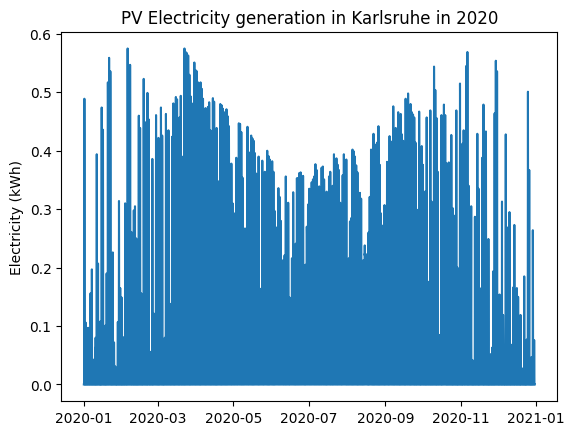

Gesamtenergieertrag in 2020 : 702.666 kWh


In [108]:
#Plot the data
plt.plot(solar_df.index, solar_df['Electricity'])
plt.ylabel('Electricity (kWh)')
plt.title('PV Electricity generation in Karlsruhe in 2020')
plt.show()

print("Gesamtenergieertrag in", year, ":" , solar_df['Electricity'].sum(), "kWh")

#### Load Household from load_profile_prediction

Here we take the foercast from one random run from Model 3. Load profile can easily be changed, by changing 'path'.

In [109]:
#load data from the correct path
path = 'd:/Dokumente/Studium/20242025 WS/WattWise/Repo/wattWise/output_load/Load_Forecast_Model_3.csv'
load_prediction = pd.read_csv(path, index_col=0, parse_dates=True)

load_prediction.head(2)

,SFH3_P_TOT_Prediction,SFH4_P_TOT_Prediction,SFH5_P_TOT_Prediction,SFH7_P_TOT_Prediction,SFH9_P_TOT_Prediction,SFH12_P_TOT_Prediction,SFH14_P_TOT_Prediction,SFH16_P_TOT_Prediction,SFH18_P_TOT_Prediction,SFH19_P_TOT_Prediction,...,SFH21_P_TOT_Prediction,SFH22_P_TOT_Prediction,SFH27_P_TOT_Prediction,SFH28_P_TOT_Prediction,SFH29_P_TOT_Prediction,SFH30_P_TOT_Prediction,SFH32_P_TOT_Prediction,SFH36_P_TOT_Prediction,SFH38_P_TOT_Prediction,SFH39_P_TOT_Prediction
2020-01-01 00:00:00+00:00,0.275533,0.279685,0.282855,0.237430,0.206651,0.220783,0.225113,0.243482,0.217372,0.278719,...,0.287348,0.250344,0.303151,0.231109,0.280396,0.221593,0.250858,0.257618,0.287838,0.297862
2020-01-01 01:00:00+00:00,0.259073,0.270441,0.257825,0.208178,0.191334,0.204621,0.202231,0.228947,0.198406,0.261355,...,0.270595,0.228662,0.276448,0.213460,0.260681,0.199582,0.226725,0.235061,0.250739,0.271704


In [110]:

load_prediction_houshehold_df = load_prediction[['SFH3_P_TOT_Prediction']].copy()
load_prediction_houshehold_df.rename(columns={'SFH3_P_TOT_Prediction': 'Load'}, inplace=True)

# Calculation with PV

In [111]:
#Check if the indices of the two DataFrames match
if not load_prediction_houshehold_df.index.equals(solar_df.index):
    raise ValueError("The indices of the two DataFrames do not match.")

In [113]:
load_withPV_df = calculate_net_load_withPV(load_prediction_houshehold_df, solar_df)

load_withPV_df

,Load,Net_Load
2020-01-01 00:00:00+00:00,0.275533,0.275533
2020-01-01 01:00:00+00:00,0.259073,0.259073
2020-01-01 02:00:00+00:00,0.267423,0.267423
2020-01-01 03:00:00+00:00,0.265780,0.265780
2020-01-01 04:00:00+00:00,0.285493,0.285493
...,...,...
2020-12-30 19:00:00+00:00,0.498445,0.498445
2020-12-30 20:00:00+00:00,0.448063,0.448063
2020-12-30 21:00:00+00:00,0.422791,0.422791
2020-12-30 22:00:00+00:00,0.399924,0.399924


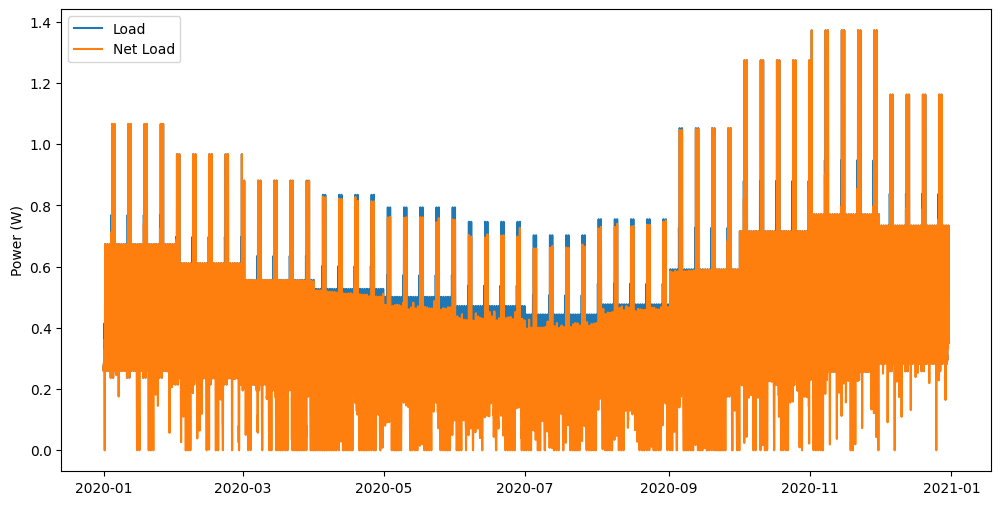

In [114]:
#print both loads as lineplot
plt.figure(figsize=(12, 6))
plt.plot(load_withPV_df.index, load_withPV_df['Load'], label='Load')
plt.plot(load_withPV_df.index, load_withPV_df['Net_Load'], label='Net Load')
plt.ylabel('Power (W)')
plt.legend()
plt.show()
